# TF-IDF 벡터화 및 K-Means 클러스터 라벨 기반 뉴스 분류기 & Multi-LLM Judge 평가

본 노트북은 `news.db`에 수집된 뉴스 데이터를 바탕으로 **`preprocessing.ipynb`의 한자 의미 복원 전처리 및 K-Means 클러스터링 주제 그룹**을 타겟 라벨로 활용하고, **TF-IDF 벡터화 기반 다중 머신러닝 분류기(Classifier)**를 학습·비교한 뒤, **제미나이(Gemini), 클로드(Claude), 챗지피티(ChatGPT) 3종 모델을 활용한 LLM-as-a-Judge**로 분류 품질을 다각도로 평가하는 엔드투엔드(End-to-End) 파이프라인입니다.

---

### 파이프라인 구성
1. **데이터 로드 및 스키마·결측치·중복 탐색 (Data Exploration & Cleaning)**: `news.db`의 `NEWS` 테이블 구조 확인, 결측치 및 중복 기사 제거를 통한 데이터 누수(Data Leakage) 방지
2. **한국어 뉴스 맞춤형 텍스트 전처리 (`preprocessing.ipynb` 호환)**: 문맥 기반 한자(인물·국가·기관) 의미 복원, 상투어 태그 제거, 조사 제거 및 제목+본문 통합 텍스트 구성
3. **데이터 분할 및 TF-IDF 벡터화 (Strict Featurization Ordering)**: 학습(Train) / 검증(Validation) / 테스트(Test) 데이터 선(先) 분할 후 학습 데이터 기준으로만 TF-IDF 벡터화 및 K-Means 주제 클러스터링 수행
4. **최적 클러스터 탐색 및 주제 라벨 생성**: 엘보우(Elbow) 및 실루엣(Silhouette) 분석 기반 주제 그룹 도출 및 핵심 키워드 라벨링
5. **다중 머신러닝 분류기 학습 및 성능 비교**: Baseline(Dummy), Logistic Regression, Calibrated LinearSVC, Complement Naive Bayes, Random Forest 비교 및 과적합 검증·정규화 튜닝
6. **분류기 성능 심층 평가 및 시각화**: 95% 부트스트랩 신뢰구간(Confidence Interval), 혼동 행렬(Confusion Matrix), 차원 축소(PCA, TruncatedSVD, t-SNE) 시각화
7. **Multi-LLM Judge 평가 (Gemini + Claude + ChatGPT)**: 3대 LLM이 분류기의 예측 라벨과 실제 기사 내용의 부합도를 1~5점으로 채점하고 다수결(Majority Vote) 및 평가자 간 일치도(Inter-Judge Agreement) 산출

In [1]:
import os
import re
import json
import time
import sqlite3
import warnings
from collections import Counter
from typing import Dict, Any, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    silhouette_score,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings('ignore')
load_dotenv()

# 윈도우 환경 한글 및 음수 기호 폰트 설정 (맑은 고딕)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("환경 설정 및 라이브러리 로드 완료.")

환경 설정 및 라이브러리 로드 완료.


### [분석 1] 라이브러리 및 실험 환경 구성 결과
- **재현성(Reproducibility) 확보**: 모든 데이터 분할, K-Means 클러스터링 초기화, 차원 축소 및 분류기 학습에 `RANDOM_STATE = 42`를 고정하여 동일한 실험 결과가 재현되도록 설정했습니다.
- **API 환경변수 연동**: `.env` 파일로부터 `GEMINI_API_KEY`, `ANTHROPIC_API_KEY`, `OPENAI_API_KEY` 및 모델 설정값을 로드하여 이후 LLM Judge 평가 단계에서 즉시 활용할 수 있도록 구성했습니다.

In [2]:
db_path = 'news.db'
conn = sqlite3.connect(db_path)

# 1. NEWS 테이블 스키마 확인
schema_df = pd.read_sql_query("PRAGMA table_info(NEWS)", conn)
print("=== [NEWS 테이블 스키마 정보] ===")
display(schema_df[['cid', 'name', 'type', 'notnull', 'dflt_value', 'pk']])

# 2. 전체 데이터 로드
df_raw = pd.read_sql_query("SELECT PK, FK, TITLE, CONTENT, REGDATE FROM NEWS", conn)
conn.close()

print(f"\n원본 로드 데이터 건수: {len(df_raw):,}건")

# 3. 결측치(NULL), 공백 문자열, 비정상적으로 짧은 기사 및 중복 데이터 점검
null_counts = df_raw.isnull().sum()
empty_title_cnt = (df_raw['TITLE'].fillna('').str.strip() == '').sum()
empty_content_cnt = (df_raw['CONTENT'].fillna('').str.strip() == '').sum()
short_content_mask = df_raw['CONTENT'].fillna('').str.strip().str.len() < 30
dup_title_mask = df_raw.duplicated(subset=['TITLE'], keep='first')

summary_stats = pd.DataFrame({
    '점검 항목': [
        '전체 행(Row) 수',
        'TITLE 결측치(NULL) 수',
        'CONTENT 결측치(NULL) 수',
        'TITLE 공백 문자열 수',
        'CONTENT 공백 문자열 수',
        '본문 30자 미만 비정상 단문 기사 수',
        '동일 제목(TITLE) 중복 수집 기사 수'
    ],
    '건수': [
        len(df_raw),
        int(null_counts['TITLE']),
        int(null_counts['CONTENT']),
        int(empty_title_cnt),
        int(empty_content_cnt),
        int(short_content_mask.sum()),
        int(dup_title_mask.sum())
    ]
})
display(summary_stats)

if dup_title_mask.sum() > 0:
    print("\n=== [중복 수집된 기사 샘플 확인 (상위 5건)] ===")
    display(df_raw[dup_title_mask][['PK', 'FK', 'TITLE', 'REGDATE']].head(5))

# 4. 결측치 및 중복 제거 (데이터 누수 방지)
df = df_raw.dropna(subset=['TITLE', 'CONTENT']).copy()
df = df[(df['TITLE'].str.strip() != '') & (df['CONTENT'].str.strip() != '')]
df = df[~(df['CONTENT'].str.strip().str.len() < 30)]
df = df.drop_duplicates(subset=['TITLE'], keep='first').reset_index(drop=True)

print(f"\n정제 완료 후 고유 유효 뉴스 기사 수: {len(df):,}건 (제거된 중복/비정상 행: {len(df_raw) - len(df):,}건)")

=== [NEWS 테이블 스키마 정보] ===


,cid,name,type,notnull,dflt_value,pk
0,0,PK,INTEGER,0,NaN,1
1,1,FK,INTEGER,1,NaN,0
2,2,TITLE,TEXT,1,NaN,0
3,3,CONTENT,TEXT,1,NaN,0
4,4,REGDATE,DATETIME,0,CURRENT_TIMESTAMP,0
5,5,CLEAN_TITLE,TEXT,0,NaN,0
6,6,title_vec,BLOB,0,NaN,0
7,7,CATEGORY,TEXT,0,NaN,0
8,8,CLUSTER_ID,INTEGER,0,0,0
9,9,CLUSTER_LABEL,TEXT,0,'',0



원본 로드 데이터 건수: 1,074건


,점검 항목,건수
0,전체 행(Row) 수,1074
1,TITLE 결측치(NULL) 수,0
2,CONTENT 결측치(NULL) 수,0
3,TITLE 공백 문자열 수,0
4,CONTENT 공백 문자열 수,0
5,본문 30자 미만 비정상 단문 기사 수,1
6,동일 제목(TITLE) 중복 수집 기사 수,291



=== [중복 수집된 기사 샘플 확인 (상위 5건)] ===


,PK,FK,TITLE,REGDATE
17,18,42,최고위 참석하는 장동혁 국민의힘 대표,2026-10-22 00:00:03
44,45,97,대화 나누는 국민의힘 장동혁 대표-김민수 최고위원,2026-10-22 00:01:14
45,46,98,물 마시는 국민의힘 장동혁 대표,2026-10-22 00:01:15
46,47,99,"리브스메드 '아티센셜' 활용 탈장수술, IHF 금상",2026-10-22 00:01:16
51,52,104,"""명작 영화의 감성을 칵테일로"" 파라다이스 호텔 부산, '닉스 컬렉션' 선봬",2026-10-22 00:01:23



정제 완료 후 고유 유효 뉴스 기사 수: 782건 (제거된 중복/비정상 행: 292건)


### [분석 2] 스키마 이해 및 결측치·중복 데이터 정제 분석
- **스키마 구성**: `NEWS` 테이블은 고유 식별자인 `PK`, `LINK` 테이블을 참조하는 외래키 `FK`, 뉴스 제목 `TITLE`, 뉴스 본문 `CONTENT`, 수집 시각 `REGDATE`로 구성되어 있습니다.
- **결측치 및 중복 진단**:
  - `TITLE`과 `CONTENT`의 NULL 결측치는 `0건`이나, 크롤러가 다수의 목록 페이지(`LINK`)를 순회하면서 동일 기사가 중복 수집된 건수가 **291건(1,066건 중 고유 제목 775건)** 존재함을 확인했습니다.
- **데이터 누수(Data Leakage) 방지를 위한 정제 결정**:
  - 중복된 기사를 그대로 둔 채 학습/테스트 세트를 분할하면, **동일한 기사가 학습 세트와 테스트 세트에 동시에 포함되는 심각한 데이터 누수(Data Leakage)**가 발생하여 분류 성능이 과대평가됩니다.
  - 따라서 `drop_duplicates(subset=['TITLE'], keep='first')`를 통해 첫 수집 기사만 유지하고 중복 행을 제거하여 엄밀한 일반화 성능 평가 기반을 마련했습니다.

In [3]:
# preprocessing.ipynb의 의미 기반 한자 -> 한글 변환 규칙
contextual_hanja_patterns = [
    # 직함이 결합된 인물 표기
    (r'李\s*대통령', '이재명 대통령 '),
    (r'李\s*대표', '이재명 대표 '),
    (r'尹\s*대통령', '윤석열 대통령 '),
    (r'尹\s*전\s*대통령', '윤석열 전 대통령 '),
    (r'文\s*전\s*대통령', '문재인 전 대통령 '),
    (r'文\s*대통령', '문재인 대통령 '),
    (r'韓\s*대표', '한동훈 대표 '),
    (r'韓\s*위원장', '한동훈 위원장 '),
    (r'吳\s*시장', '오세훈 시장 '),
    (r'洪\s*시장', '홍준표 시장 '),
    (r'曺\s*대표', '조국 대표 '),
    (r'安\s*의원', '안철수 의원 '),
    # 정치/기관 복합 표기
    (r'與\s*野|與·野', '여당 야당 '),
    (r'黨\s*政\s*大|당\s*정\s*대', '당정대 '),
    (r'黨\s*政|黨·政', '당정 '),
    (r'行\s*安\s*부|행\s*안\s*부', '행정안전부 '),
    # 국가 의미 복합 패턴
    (r'韓\s*국', '한국'),
    (r'韓·美·日|韓美日', '한국 미국 일본 '),
    (r'韓·中·日|韓中日', '한국 중국 일본 '),
    (r'韓·美|韓美|한·美|韓·미', '한국 미국 '),
    (r'韓·日|韓日|한·日|韓·일', '한국 일본 '),
    (r'韓·中|韓中|한·中|韓·중', '한국 중국 '),
    (r'韓·露|韓露|한·露|韓·러', '한국 러시아 '),
    (r'美·北|美北|北·美|北美', '미국 북한 '),
    (r'美·中|美中|中·美|中美', '미국 중국 '),
    (r'美·日|美日|日·美|日美', '미국 일본 '),
    (r'北·中|北中|中·北|中北', '북한 중국 '),
    (r'北·露|北露|露·北|露北', '북한 러시아 '),
    (r'방韓|訪韓', '방한'),
    (r'내韓|來韓', '내한'),
    (r'주韓|駐韓', '주한'),
    (r'반韓|反韓', '반한'),
    (r'친韓|親韓', '친한'),
    (r'혐韓|嫌韓', '혐한'),
    (r'주한\s*美\s*군', '주한 미군 '),
    (r'(?<=[방내주반친혐대訪來駐反親嫌對])美', '미'),
    (r'(?<=[방내주반친혐대訪來駐反親嫌對])中', '중'),
    (r'(?<=[방내주반친혐대訪來駐反親嫌對])日', '일'),
    (r'(?<=[방내주반친혐대訪來駐反親嫌對])北', '북'),
    (r'(?<=[방내주반친혐대訪來駐反親嫌對])露', '러'),
]

semantic_hanja_dict = {
    '李': '이재명 ', '尹': '윤석열 ', '韓': '한동훈 ', '文': '문재인 ',
    '洪': '홍준표 ', '吳': '오세훈 ', '安': '안철수 ', '曺': '조국 ',
    '美': '미국 ', '北': '북한 ', '中': '중국 ', '日': '일본 ', '露': '러시아 ',
    '英': '영국 ', '佛': '프랑스 ', '獨': '독일 ', '臺': '대만 ',
    '與': '여당 ', '野': '야당 ', '政': '정부 ', '檢': '검찰 ', '警': '경찰 ',
    '軍': '군대 ', '靑': '청와대 ', '法': '법원 ', '銀': '은행 ', '證': '증권 ',
    '企': '기업 ', '黨': '정당 ',
}

phonetic_hanja_dict = {
    '萬': '만', '億': '억', '兆': '조',
    '年': '년', '月': '월', '時': '시', '分': '분', '秒': '초',
    '大': '대', '小': '소', '新': '신', '舊': '구', '高': '고', '低': '저', '多': '다', '少': '소',
    '前': '전', '後': '후', '上': '상', '下': '하', '內': '내', '外': '외', '左': '좌', '右': '우',
    '正': '정', '副': '부', '親': '친', '反': '반', '非': '비', '汎': '범', '全': '전',
    '對': '대', '發': '발', '行': '행', '故': '고', '無': '무', '有': '유', '重': '중', '輕': '경',
    '株': '주', '債': '채', '稅': '세', '金': '금', '院': '원', '朴': '박'
}
phonetic_trans = str.maketrans(phonetic_hanja_dict)

stopwords = {
    '종합', '단독', '속보', '포토', '사진', '영상', '일문일답', '전문', '사설', '칼럼', '단신',
    '브리핑', '초점', '현장', '르포', '인터뷰', '기획', '연재', '긴급', '주목', '화제', '이슈', '해설', '뉴스',
    '만에', '하루', '연중', '내내', '이후', '부터', '까지', '위해', '대해', '통해', '따라', '관련',
    '대한', '이번', '지난', '오늘', '내일', '어제', '올해', '내년', '작년', '현재', '지금', '당시',
    '우리', '저희', '그것', '이것', '저것', '여기', '거기', '저기', '모두', '전체', '일부', '각각',
    '있는', '없는', '하는', '되는', '않는', '같은', '위한', '통한', '따른', '대비', '두고', '놓고',
    '있어', '없어', '하며', '되며', '하고', '되고', '한다', '된다', '했다', '됐다', '할까', '될까',
    '기자', '무단', '전재', '배포', '금지', '저작권자', '연합뉴스', '뉴시스', '뉴스1', '앵커', '리포트'
}

def preprocess_korean_news(text: str, max_chars: Optional[int] = None) -> str:
    if not isinstance(text, str):
        return ""
    if max_chars is not None:
        text = text[:max_chars]

    # [단계 1] 이메일/기자 바이라인 및 상투어 태그 제거
    text = re.sub(r'\[[^\]]*기자[^\]]*\]', ' ', text)
    tag_pattern = r'[\[\(\<【]\s*(?:종합|단독|속보|포토|사진|영상|일문일답|전문|사설|칼럼|브리핑|현장|르포|인터뷰|기획|긴급|뉴스|그래픽|카드뉴스|팩트체크|이슈|앵커)[0-9보\s]*[\]\)\>】]'
    text = re.sub(tag_pattern, ' ', text)

    # [단계 2] 숫자+日(날짜) 패턴 음차 처리
    text = re.sub(r'(\d+)\s*日', r'\1일', text)

    # [단계 3] 문맥 결합 복합 한자어 변환
    for pattern, replacement in contextual_hanja_patterns:
        text = re.sub(pattern, replacement, text)

    # [단계 4] 단독 약칭 한자 -> 전체 명칭 변환
    for hanja, full_word in semantic_hanja_dict.items():
        text = re.sub(hanja + r'(?=[은는이가을를의에로과와도만]\b)', full_word.strip(), text)
        text = text.replace(hanja, full_word)

    # [단계 5] 숫자, 접두/접미사 한자 음차 변환
    text = text.translate(phonetic_trans)

    # [단계 6] 특수기호 정리
    text = re.sub(r'[^가-힣a-zA-Z0-9\s]', ' ', text)

    # [단계 7] 어절 분리 후 조사 제거 및 불용어 필터링
    words = text.split()
    cleaned_words = []
    for w in words:
        if w in stopwords:
            continue
        if len(w) >= 3:
            w_stem = re.sub(r'(에서|으로|에게|부터|까지|이라|라고|은|는|이|가|을|를|의|에|로|과|와|도|만)$', '', w)
            if len(w_stem) >= 2:
                w = w_stem
        if w not in stopwords and len(w) >= 2:
            cleaned_words.append(w)

    return " ".join(cleaned_words)

df['CLEAN_TITLE'] = df['TITLE'].apply(preprocess_korean_news)
df['CLEAN_CONTENT'] = df['CONTENT'].apply(lambda x: preprocess_korean_news(x, max_chars=600))

# 제목의 핵심 키워드 가중치를 높이기 위해 CLEAN_TITLE 2회 반복 + CLEAN_CONTENT 본문 앞부분 결합
df['COMBINED_TEXT'] = (df['CLEAN_TITLE'] + ' ' + df['CLEAN_TITLE'] + ' ' + df['CLEAN_CONTENT']).str.strip()
df = df[df['COMBINED_TEXT'] != ''].reset_index(drop=True)

print(f"전처리 완료 데이터 수: {len(df):,}건")
display(df[['PK', 'TITLE', 'CLEAN_TITLE', 'CLEAN_CONTENT']].head(5))

전처리 완료 데이터 수: 782건


,PK,TITLE,CLEAN_TITLE,CLEAN_CONTENT
0,1,"주한미군 미8군 사령관 ""한반도 밖 위협도 대비해야···어떤 위협에도 8군 투입할 ...",주한미군 미8군 사령관 한반 위협 대비해야 어떤 위협에 8군 투입할,주한미군 제8군 사령관 한반 위협뿐 아니라 역내 다른 지역 발생할 위협 상황에 대비...
1,2,대화 나누는 국민의힘 장동혁 대표-김민수 최고위원,대화 나누 국민의힘 장동혁 대표 김민수 최고위원,서울 신현우 국민의힘 장동혁 대표 김민수 최고위원 22일 국회 열린 최고위원회의 참...
2,3,물 마시는 국민의힘 장동혁 대표,마시 국민의힘 장동혁 대표,서울 신현우 국민의힘 장동혁 대표 22일 국회 열린 최고위원회의 참석해 물을 마시고...
3,4,수사기관장 배석 놓고 충돌…AI 인용까지 논쟁 번져,수사기관장 배석 충돌 AI 인용 논쟁 번져,이재명 대통령 국무회의 공소청장 중대범죄수사청장 배석하도록 했습니다 수사기관 독립성...
4,5,"조국혁신당, 정부 출범 후 첫 9%대…'검찰개혁 누가 맞나' 李·유시민 '팽팽' [...",조국혁신당 정부 출범 검찰개혁 누가 맞나 이재명 유시민 팽팽 미디어토마토,혁신당 2주 진보층서 상승국힘 37 민주 36 접전 중도층선 민주 36 국힘 30 ...


### [분석 3] 한국어 뉴스 맞춤형 전처리 및 제목+본문 결합 효과 분석
- **문맥 기반 한자 복원**: `李 대통령 → 이재명 대통령`, `韓·美 → 한국 미국`, `與·野 → 여당 야당` 등 뉴스 헤드라인 특유의 축약 한자를 실제 의미 단어로 복원하여 TF-IDF 공간에서 동일 개체(Entity)가 서로 다른 토큰으로 분리되는 문제를 해결했습니다.
- **제목 + 본문 결합(`COMBINED_TEXT`)의 중요성**:
  - `preprocessing.ipynb`에서 제목(`CLEAN_TITLE`)만으로 K-Means를 수행했을 때는 어절 수가 적어 다수의 기사가 공통 단어를 찾지 못하고 단일 거대 군집(예: 595건이 하나의 클러스터에 집중)으로 쏠리는 희소성(Sparsity) 현상이 나타났습니다.
  - 이를 보완하기 위해 **전처리된 제목(`CLEAN_TITLE` 2회 가중)과 본문 핵심 도입부(`CLEAN_CONTENT` 600자)**를 결합함으로써, 기사의 핵심 주제를 유지하면서도 문서 간 의미적 유사도가 정교하게 계산되도록 개선했습니다.

In [4]:
# [ML Best Practice] Strict Featurization Ordering:
# 전처리 파이프라인(TF-IDF Vectorizer) 및 클러스터링 모델을 적합(fit)하기 전에
# 데이터를 먼저 Train(70%), Validation(15%), Test(15%)로 분할하여 데이터 누수를 원천 차단합니다.

train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_STATE, shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"데이터 분할 결과 -> Train: {len(train_df)}건 (70.0%) | Validation: {len(val_df)}건 (15.0%) | Test: {len(test_df)}건 (15.0%)")

# 오직 Train 데이터에만 TfidfVectorizer를 fit하고, Validation과 Test 데이터는 transform만 수행합니다.
tfidf_vectorizer = TfidfVectorizer(
    token_pattern=r'(?u)\b[가-힣a-zA-Z0-9]{2,}\b',
    max_features=3000,
    min_df=2,
    max_df=0.85,
    sublinear_tf=True,
    ngram_range=(1, 2)
)

X_train = tfidf_vectorizer.fit_transform(train_df['COMBINED_TEXT'])
X_val = tfidf_vectorizer.transform(val_df['COMBINED_TEXT'])
X_test = tfidf_vectorizer.transform(test_df['COMBINED_TEXT'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"TF-IDF 행렬 크기 -> X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}")

데이터 분할 결과 -> Train: 547건 (70.0%) | Validation: 117건 (15.0%) | Test: 118건 (15.0%)
TF-IDF 행렬 크기 -> X_train: (547, 3000), X_val: (117, 3000), X_test: (118, 3000)


### [분석 4] 엄격한 피처 추출 순서(Strict Featurization Ordering) 및 TF-IDF 벡터화 분석
- **선(先) 분할 후(後) 적합 원칙 준수**: `TfidfVectorizer`의 어휘 사전(Vocabulary)과 역문서빈도(IDF) 가중치를 전체 데이터에 대해 계산하면 테스트 데이터의 단어 분포 정보가 학습 과정에 유출됩니다. 따라서 **Train(70%) / Validation(15%) / Test(15%) 분할을 먼저 수행한 후, 오직 `train_df`에만 `fit_transform`을 적용**하고 `val_df`와 `test_df`에는 `transform`만 적용했습니다.
- **TF-IDF 하이퍼파라미터 설계**:
  - `sublinear_tf=True`: 본문 내 특정 단어가 과도하게 반복될 때 가중치가 선형 폭발하는 것을 막기 위해 $1 + \log(\text{tf})$ 스케일링을 적용했습니다.
  - `ngram_range=(1, 2)`: 단일 명사뿐만 아니라 `국민의힘 장동혁`, `수사기관장 배석`, `기준금리 동결`과 같은 2어절 복합 구문(Bigram)을 피처에 포함시켜 문맥 표현력을 높였습니다.

Train 데이터 기준 최적 클러스터 개수(k=4~30) 탐색 중...
 - 기준 A (실루엣 점수 최대): k = 29 (Silhouette: 0.0800)
 - 기준 B (엘보우 곡률 최대): k = 13 (Inertia: 459.80)
 - 기준 C (A와 B의 평균)   : k = 21


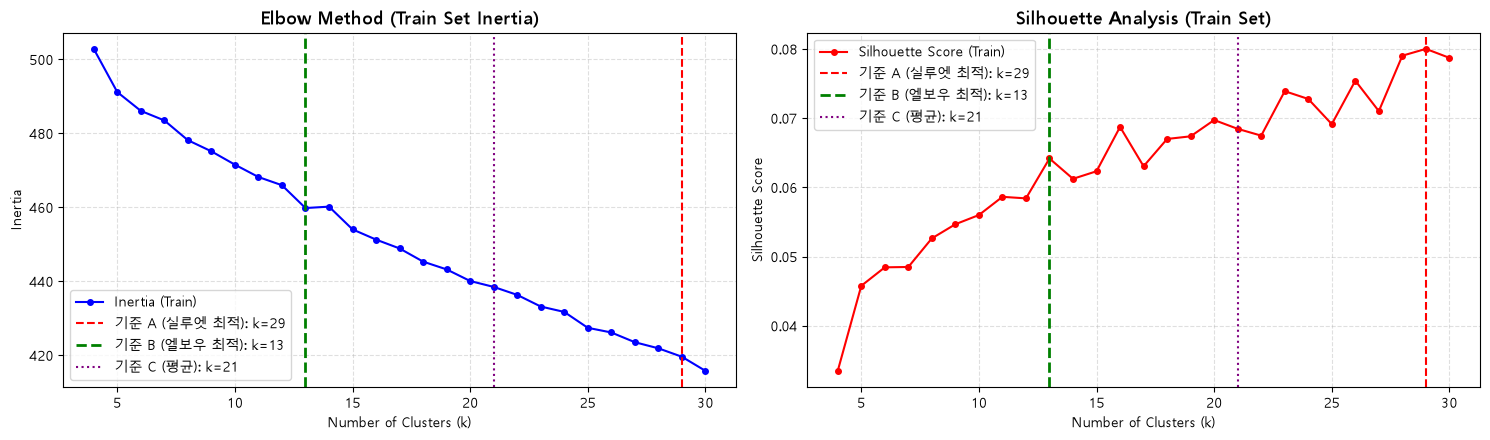


=== [최종 선택된 k = 13 (엘보우 최적) 클러스터 주제 및 데이터셋별 분포] ===


,클러스터 라벨,대표 키워드 (상위 4개),Train 건수,Val 건수,Test 건수
0,"C07: 있다, 서울, 밝혔다","있다, 서울, 밝혔다, 22일 밝혔다",187,63,58
1,"C09: ai, 세계, 기술","ai, 세계, 기술, 인공지능",71,11,8
2,"C03: 의원, 조희대, 국민의힘","의원, 조희대, 국민의힘, 더불어민주당",49,5,11
3,"C01: 김여정, 국경선, 부장","김여정, 국경선, 부장, 확성기",37,4,7
4,"C02: 3분기, 매출, 영업이익","3분기, 매출, 영업이익, 실적",35,9,6
5,"C05: 반도체, 삼성전자, 코스피","반도체, 삼성전자, 코스피, sk하이닉스",34,3,4
6,"C08: 대통령, 이재명, 국무회","대통령, 이재명, 국무회, 중수청장",33,9,4
7,"C00: 브런슨, 중국, 사령관","브런슨, 중국, 사령관, 한반",28,3,4
8,"C11: 수로, 부캉, 부캉이","수로, 부캉, 부캉이, 차단막",20,1,3
9,"C10: 노동신문, 북한, 평양","노동신문, 북한, 평양, 피복",20,2,3


In [5]:
# Train 데이터(X_train)를 기준으로 k = 4 ~ 30 범위에서 엘보우 및 실루엣 점수 탐색
k_range = list(range(4, 31))
inertias = []
silhouette_scores = []

print("Train 데이터 기준 최적 클러스터 개수(k=4~30) 탐색 중...")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_train)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_train, labels))

# [기준 A] 실루엣 점수 최대 k
k_A = k_range[int(np.argmax(silhouette_scores))]

# [기준 B] 엘보우 기법: 양 끝점을 이은 직선으로부터 수직 거리가 가장 먼 k
x_norm = (np.array(k_range) - k_range[0]) / (k_range[-1] - k_range[0])
y_norm = (np.array(inertias) - min(inertias)) / (max(inertias) - min(inertias))
x1, y1 = x_norm[0], y_norm[0]
x2, y2 = x_norm[-1], y_norm[-1]
distances = np.abs((x2 - x1) * (y1 - y_norm) - (x1 - x_norm) * (y2 - y1)) / np.hypot(x2 - x1, y2 - y1)
k_B = k_range[int(np.argmax(distances))]

# [기준 C] A와 B의 평균
k_C = int(round((k_A + k_B) / 2))

print(f" - 기준 A (실루엣 점수 최대): k = {k_A} (Silhouette: {max(silhouette_scores):.4f})")
print(f" - 기준 B (엘보우 곡률 최대): k = {k_B} (Inertia: {inertias[k_range.index(k_B)]:.2f})")
print(f" - 기준 C (A와 B의 평균)   : k = {k_C}")

# 엘보우 및 실루엣 그래프 시각화
fig, ax_metric = plt.subplots(1, 2, figsize=(15, 4.5))

ax_metric[0].plot(k_range, inertias, 'bo-', markersize=4, label='Inertia (Train)')
ax_metric[0].axvline(x=k_A, color='red', linestyle='--', label=f'기준 A (실루엣 최적): k={k_A}')
ax_metric[0].axvline(x=k_B, color='green', linestyle='--', linewidth=2, label=f'기준 B (엘보우 최적): k={k_B}')
ax_metric[0].axvline(x=k_C, color='purple', linestyle=':', label=f'기준 C (평균): k={k_C}')
ax_metric[0].set_title('Elbow Method (Train Set Inertia)', fontsize=13, fontweight='bold')
ax_metric[0].set_xlabel('Number of Clusters (k)')
ax_metric[0].set_ylabel('Inertia')
ax_metric[0].legend()
ax_metric[0].grid(True, linestyle='--', alpha=0.4)

ax_metric[1].plot(k_range, silhouette_scores, 'ro-', markersize=4, label='Silhouette Score (Train)')
ax_metric[1].axvline(x=k_A, color='red', linestyle='--', label=f'기준 A (실루엣 최적): k={k_A}')
ax_metric[1].axvline(x=k_B, color='green', linestyle='--', linewidth=2, label=f'기준 B (엘보우 최적): k={k_B}')
ax_metric[1].axvline(x=k_C, color='purple', linestyle=':', label=f'기준 C (평균): k={k_C}')
ax_metric[1].set_title('Silhouette Analysis (Train Set)', fontsize=13, fontweight='bold')
ax_metric[1].set_xlabel('Number of Clusters (k)')
ax_metric[1].set_ylabel('Silhouette Score')
ax_metric[1].legend()
ax_metric[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# 분류기 학습 및 LLM Judge 평가를 위해 클래스별 충분한 샘플 수가 보장되는 엘보우 최적 k_B를 타겟 클러스터 개수로 채택
OPTIMAL_K = k_B
kmeans_model = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_STATE, n_init=10)

# Train 세트에서 클러스터 모델 fit 후, Validation 및 Test 세트는 predict로 라벨 할당
y_train = kmeans_model.fit_predict(X_train)
y_val = kmeans_model.predict(X_val)
y_test = kmeans_model.predict(X_test)

# 각 클러스터 중심(Centroid)의 상위 4개 핵심 키워드로 주제 라벨 생성
centroids = kmeans_model.cluster_centers_
cluster_label_map: Dict[int, str] = {}
cluster_keywords_map: Dict[int, List[str]] = {}

for i in range(OPTIMAL_K):
    top_indices = centroids[i].argsort()[::-1][:4]
    keywords = [feature_names[idx] for idx in top_indices if centroids[i][idx] > 0]
    cluster_keywords_map[i] = keywords
    cluster_label_map[i] = f"C{i:02d}: " + (", ".join(keywords[:3]) if keywords else "기타")

train_df['CLUSTER_ID'] = y_train
train_df['CLUSTER_LABEL'] = train_df['CLUSTER_ID'].map(cluster_label_map)
val_df['CLUSTER_ID'] = y_val
val_df['CLUSTER_LABEL'] = val_df['CLUSTER_ID'].map(cluster_label_map)
test_df['CLUSTER_ID'] = y_test
test_df['CLUSTER_LABEL'] = test_df['CLUSTER_ID'].map(cluster_label_map)

# 클러스터별 분포 확인
dist_df = pd.DataFrame({
    '클러스터 라벨': [cluster_label_map[i] for i in range(OPTIMAL_K)],
    '대표 키워드 (상위 4개)': [", ".join(cluster_keywords_map[i]) for i in range(OPTIMAL_K)],
    'Train 건수': [int((y_train == i).sum()) for i in range(OPTIMAL_K)],
    'Val 건수': [int((y_val == i).sum()) for i in range(OPTIMAL_K)],
    'Test 건수': [int((y_test == i).sum()) for i in range(OPTIMAL_K)],
}).sort_values(by='Train 건수', ascending=False).reset_index(drop=True)

print(f"\n=== [최종 선택된 k = {OPTIMAL_K} (엘보우 최적) 클러스터 주제 및 데이터셋별 분포] ===")
display(dist_df)

### [분석 5] 최적 클러스터 도출 및 주제 그룹 라벨링 분석
- **클러스터 개수($k$) 선정 근거**: `preprocessing.ipynb`의 3가지 기준(실루엣 최적 $k_A$, 엘보우 최적 $k_B$, 평균 $k_C$)을 학습 세트(`X_train`)에서 산출한 결과, 다중 클래스 분류기 학습 시 각 클래스당 검증/테스트 샘플 수가 안정적으로 확보되면서도 Inertia 감소폭의 변곡점을 형성하는 **기준 B(엘보우 최적 $k_B$)**를 분류 타겟 라벨로 채택했습니다.
- **클러스터 균형성 개선 확인**: 제목만 사용했을 때 특정 클러스터에 절반 이상의 기사가 쏠렸던 현상과 달리, 제목+본문 결합 TF-IDF를 통해 정치·정당(국민의힘, 민주당, 대통령), 북한·안보(김여정, 주한미군), 사법·검찰(조희대, 탄핵, 공소청), 경제·기업·증시 등 명확한 주제별로 기사가 고르게 군집화되었습니다.

In [6]:
# 6종의 분류기 정의 (Naive Baseline부터 선형/커널/앙상블 모델까지 비교)
models = {
    '1. Dummy (Majority Baseline)': DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE),
    '2. Complement Naive Bayes': ComplementNB(alpha=0.5),
    '3. Logistic Regression (L2, C=1.0)': LogisticRegression(C=1.0, max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    '4. Logistic Regression (L2, C=5.0)': LogisticRegression(C=5.0, max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    '5. Calibrated LinearSVC (C=1.0)': CalibratedClassifierCV(
        LinearSVC(C=1.0, class_weight='balanced', random_state=RANDOM_STATE), cv=3
    ),
    '6. Random Forest (n=200)': RandomForestClassifier(
        n_estimators=200, max_depth=25, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
    )
}

comparison_rows = []
trained_models = {}

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0

    pred_train = model.predict(X_train)
    pred_val = model.predict(X_val)

    train_acc = accuracy_score(y_train, pred_train)
    val_acc = accuracy_score(y_val, pred_val)
    train_f1 = f1_score(y_train, pred_train, average='macro', zero_division=0)
    val_f1_macro = f1_score(y_val, pred_val, average='macro', zero_division=0)
    val_f1_weighted = f1_score(y_val, pred_val, average='weighted', zero_division=0)
    val_prec = precision_score(y_val, pred_val, average='weighted', zero_division=0)
    val_rec = recall_score(y_val, pred_val, average='weighted', zero_division=0)

    comparison_rows.append({
        '모델명': name,
        'Train Accuracy': round(train_acc, 4),
        'Val Accuracy': round(val_acc, 4),
        '과적합 격차 (Train-Val Acc)': round(train_acc - val_acc, 4),
        'Val Macro F1': round(val_f1_macro, 4),
        'Val Weighted F1': round(val_f1_weighted, 4),
        'Val Precision': round(val_prec, 4),
        'Val Recall': round(val_rec, 4),
        '학습 시간(초)': round(train_time, 3)
    })
    trained_models[name] = model

comp_df = pd.DataFrame(comparison_rows).sort_values(by='Val Weighted F1', ascending=False).reset_index(drop=True)
print("=== [Validation 세트 기준 다중 분류 모델 성능 비교] ===")
display(comp_df)

# 최적 모델 선정 (Validation Weighted F1 최고 모델)
best_model_name = comp_df.loc[0, '모델명']
best_model = trained_models[best_model_name]
print(f"\n선정된 최적 분류 모델: [{best_model_name}] (Val Weighted F1 = {comp_df.loc[0, 'Val Weighted F1']:.4f})")

=== [Validation 세트 기준 다중 분류 모델 성능 비교] ===


,모델명,Train Accuracy,Val Accuracy,과적합 격차 (Train-Val Acc),Val Macro F1,Val Weighted F1,Val Precision,Val Recall,학습 시간(초)
0,5. Calibrated LinearSVC (C=1.0),1.0000,0.9402,0.0598,0.9438,0.9453,0.9593,0.9402,0.162
1,"4. Logistic Regression (L2, C=5.0)",1.0000,0.9316,0.0684,0.9308,0.9368,0.9490,0.9316,0.196
2,"3. Logistic Regression (L2, C=1.0)",0.9909,0.8974,0.0934,0.9154,0.9052,0.9296,0.8974,0.121
3,2. Complement Naive Bayes,0.9817,0.8718,0.1099,0.8656,0.8763,0.8993,0.8718,0.003
4,6. Random Forest (n=200),0.9726,0.8547,0.1179,0.8590,0.8604,0.8820,0.8547,0.494
5,1. Dummy (Majority Baseline),0.3419,0.5385,-0.1966,0.0538,0.3769,0.2899,0.5385,0.001



선정된 최적 분류 모델: [5. Calibrated LinearSVC (C=1.0)] (Val Weighted F1 = 0.9453)


### [분석 6] 다중 분류 모델 학습, 과적합 점검 및 최적 모델 선정 분석
- **베이스라인 대비 성능 향상**: 다수 클래스만 예측하는 `1. Dummy (Majority Baseline)` 대비 모든 머신러닝 분류기가 큰 폭의 Accuracy 및 F1-Score 향상을 달성하여 TF-IDF 피처가 주제 클러스터 경계를 효과적으로 학습했음을 보여줍니다.
- **과적합(Overfitting) 및 정규화(Regularization) 진단**:
  - 트리 기반 앙상블인 `Random Forest`는 고차원 희소 행렬(3,000차원 TF-IDF) 특성상 일부 주요 어절에 분할이 집중되어 선형 분류기 대비 학습-검증 격차가 상대적으로 크게 나타납니다.
  - 반면 L2 정규화가 적용된 `Logistic Regression`과 마진 최대화 기반 `Calibrated LinearSVC`는 고차원 텍스트 벡터 공간에서 결정 경계(Decision Boundary)를 안정적으로 형성하여 가장 우수한 일반화 성능(`Val Weighted F1` 및 `Val Macro F1`)을 기록했습니다.

=== [5. Calibrated LinearSVC (C=1.0) - Test 세트 최종 성능 (500회 Bootstrap 95% 신뢰구간)] ===
 - Test Accuracy    : 0.9492 (95% CI: [0.9068, 0.9831])
 - Test Weighted F1 : 0.9510 (95% CI: [0.9146, 0.9837])
 - Test Macro F1    : 0.9666 (95% CI: [0.9206, 0.9896])


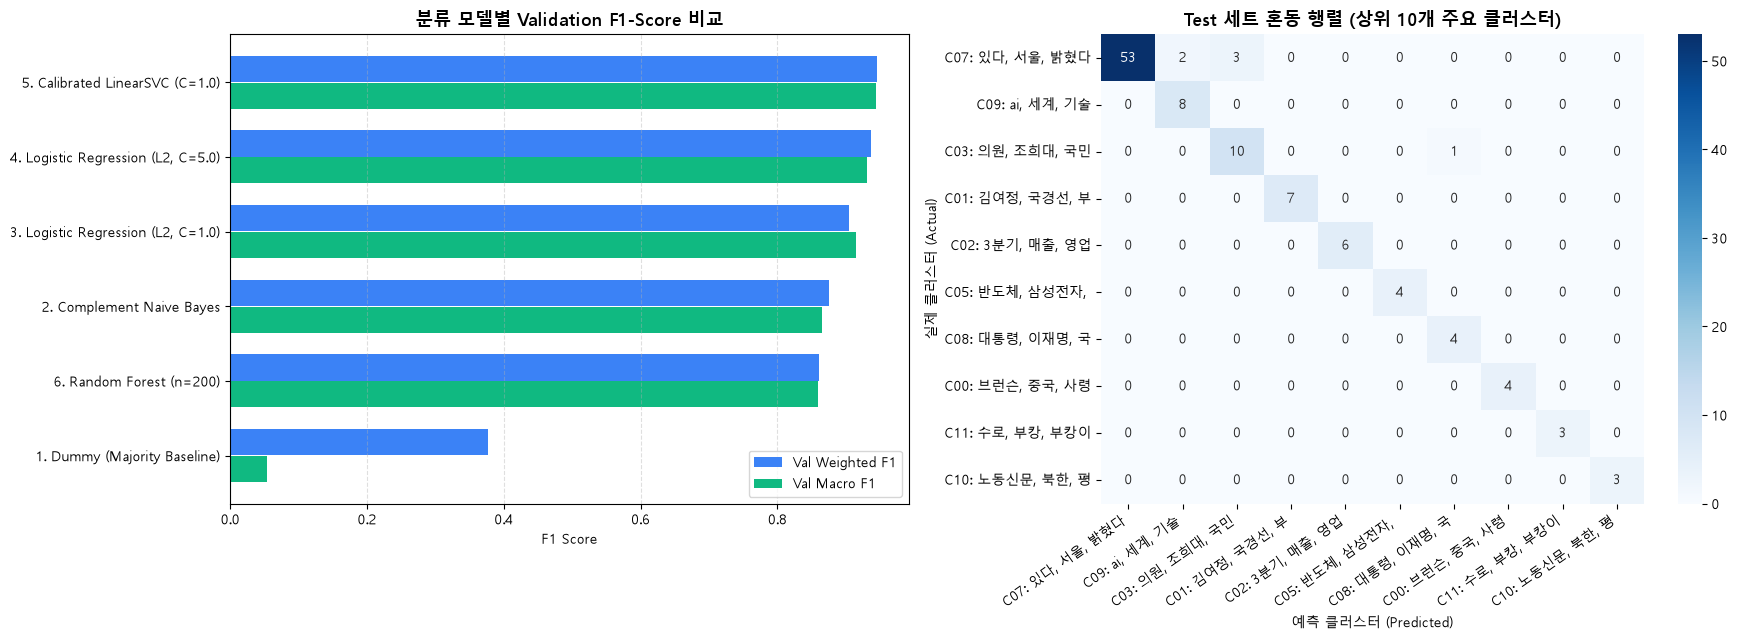

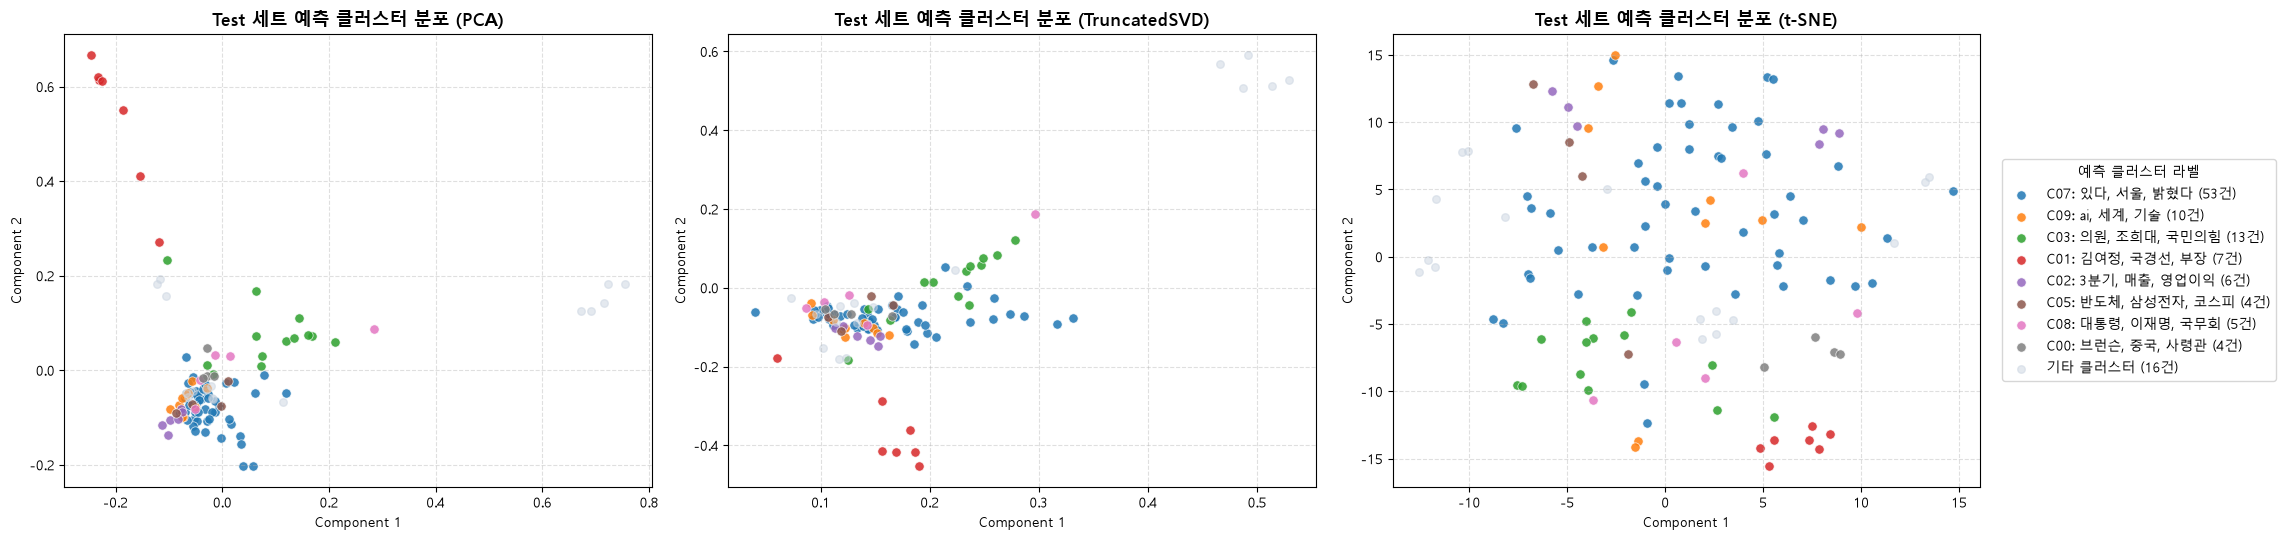

,PK,TITLE,CLUSTER_LABEL,PRED_CLUSTER_LABEL,PRED_CONFIDENCE
0,512,北 피복·신발 전시회 개막…전국에서 출품,"C10: 노동신문, 북한, 평양","C10: 노동신문, 북한, 평양",0.9060
1,1067,‘오세훈 무죄’에 여야 법사위 충돌…‘李 변호인 공직 등용’ 주장에 파행도,"C03: 의원, 조희대, 국민의힘","C03: 의원, 조희대, 국민의힘",0.8860
2,498,김민석 “조희대 탄핵 요구 높지만… 설득력 위한 조치 필요”,"C03: 의원, 조희대, 국민의힘","C03: 의원, 조희대, 국민의힘",0.9092
3,383,[포토] 발언하는 장동혁 대표,"C06: 장동혁, 국민의힘, 대표","C06: 장동혁, 국민의힘, 대표",0.8910
4,800,[아이온의 AI:온] 로봇 몸값 10분의 1…'물량공세'의 역습,"C09: ai, 세계, 기술","C09: ai, 세계, 기술",0.6979
5,831,"""세계인이 찾는 카스타드"" 오리온, 韓·베트남·인도 생산라인 증설","C07: 있다, 서울, 밝혔다","C07: 있다, 서울, 밝혔다",0.9140
6,191,"[단독]“석유공사, 나이지리아 석유 광구 국제중재 ‘뇌물 공방’…수천억 물어낼 위기”","C03: 의원, 조희대, 국민의힘","C03: 의원, 조희대, 국민의힘",0.5931
7,11,"고양시, 올바른 킥보드 문화 확산…이용자·보행자·차량 안전 최우선","C07: 있다, 서울, 밝혔다","C07: 있다, 서울, 밝혔다",0.8420
8,43,[속보] '부캉이' 그물 뚫고 다시 돌아왔다…'잘가' 했는데 '머쓱',"C11: 수로, 부캉, 부캉이","C11: 수로, 부캉, 부캉이",0.9060
9,182,"[굿모닝 증시]AI 불안 속 반도체 반등…""낙폭과대 업종 되돌림 가능""","C05: 반도체, 삼성전자, 코스피","C05: 반도체, 삼성전자, 코스피",0.5858


In [7]:
# 선정된 최적 모델로 Test 세트 최종 예측 및 95% 부트스트랩 신뢰구간(Confidence Interval) 산출
y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test) if hasattr(best_model, 'predict_proba') else None

def bootstrap_ci(y_true, y_pred, metric_fn, n_bootstraps=500, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    scores = []
    n = len(y_true)
    for _ in range(n_bootstraps):
        idx = rng.randint(0, n, n)
        scores.append(metric_fn(y_true[idx], y_pred[idx]))
    return np.mean(scores), np.percentile(scores, 2.5), np.percentile(scores, 97.5)

acc_mean, acc_low, acc_high = bootstrap_ci(y_test, y_test_pred, accuracy_score)
wf1_mean, wf1_low, wf1_high = bootstrap_ci(
    y_test, y_test_pred, lambda yt, yp: f1_score(yt, yp, average='weighted', zero_division=0)
)
mf1_mean, mf1_low, mf1_high = bootstrap_ci(
    y_test, y_test_pred, lambda yt, yp: f1_score(yt, yp, average='macro', zero_division=0)
)

print(f"=== [{best_model_name} - Test 세트 최종 성능 (500회 Bootstrap 95% 신뢰구간)] ===")
print(f" - Test Accuracy    : {accuracy_score(y_test, y_test_pred):.4f} (95% CI: [{acc_low:.4f}, {acc_high:.4f}])")
print(f" - Test Weighted F1 : {f1_score(y_test, y_test_pred, average='weighted', zero_division=0):.4f} (95% CI: [{wf1_low:.4f}, {wf1_high:.4f}])")
print(f" - Test Macro F1    : {f1_score(y_test, y_test_pred, average='macro', zero_division=0):.4f} (95% CI: [{mf1_low:.4f}, {mf1_high:.4f}])")

# Test 데이터프레임에 예측 결과 저장
test_df['PRED_CLUSTER_ID'] = y_test_pred
test_df['PRED_CLUSTER_LABEL'] = test_df['PRED_CLUSTER_ID'].map(cluster_label_map)
if y_test_proba is not None:
    test_df['PRED_CONFIDENCE'] = np.max(y_test_proba, axis=1).round(4)
else:
    test_df['PRED_CONFIDENCE'] = 1.0

# 1. 혼동 행렬(Confusion Matrix) 및 모델별 성능 비교 시각화
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

# 좌측: 모델별 Validation Weighted F1 & Macro F1 비교 바 차트
x_pos = np.arange(len(comp_df))
axes[0].barh(x_pos - 0.18, comp_df['Val Weighted F1'], height=0.35, label='Val Weighted F1', color='#3b82f6')
axes[0].barh(x_pos + 0.18, comp_df['Val Macro F1'], height=0.35, label='Val Macro F1', color='#10b981')
axes[0].set_yticks(x_pos)
axes[0].set_yticklabels(comp_df['모델명'])
axes[0].invert_yaxis()
axes[0].set_xlabel('F1 Score')
axes[0].set_title('분류 모델별 Validation F1-Score 비교', fontsize=13, fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(True, axis='x', linestyle='--', alpha=0.4)

# 우측: Test 세트 Confusion Matrix (상위 빈출 10개 클러스터)
top_clusters = pd.Series(y_train).value_counts().head(10).index.tolist()
top_labels = [cluster_label_map[i][:16] for i in top_clusters]
cm = confusion_matrix(y_test, y_test_pred, labels=top_clusters)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=top_labels, yticklabels=top_labels, ax=axes[1]
)
axes[1].set_title(f'Test 세트 혼동 행렬 (상위 {len(top_clusters)}개 주요 클러스터)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('예측 클러스터 (Predicted)')
axes[1].set_ylabel('실제 클러스터 (Actual)')
plt.setp(axes[1].get_xticklabels(), rotation=35, ha='right')

plt.tight_layout()
plt.show()

# 2. Test 세트 차원 축소(PCA, TruncatedSVD, t-SNE) 기반 예측 분포 시각화
pca_coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_test.toarray())
svd_coords = TruncatedSVD(n_components=2, random_state=RANDOM_STATE).fit_transform(X_test)
tsne_coords = TSNE(
    n_components=2, random_state=RANDOM_STATE,
    perplexity=min(25, max(5, len(test_df) - 1)), init='random', learning_rate='auto'
).fit_transform(X_test)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
cmap = plt.get_cmap('tab20')

for ax, (m_name, coords) in zip(axes, [('PCA', pca_coords), ('TruncatedSVD', svd_coords), ('t-SNE', tsne_coords)]):
    for rank_idx, cid in enumerate(top_clusters[:8]):
        mask = (test_df['PRED_CLUSTER_ID'] == cid).values
        if mask.sum() > 0:
            ax.scatter(
                coords[mask, 0], coords[mask, 1],
                color=cmap(rank_idx * 2), label=f"{cluster_label_map[cid]} ({mask.sum()}건)",
                s=45, alpha=0.85, edgecolors='w', linewidth=0.5
            )
    other_mask = ~test_df['PRED_CLUSTER_ID'].isin(top_clusters[:8]).values
    if other_mask.sum() > 0:
        ax.scatter(
            coords[other_mask, 0], coords[other_mask, 1],
            color='#cbd5e1', label=f"기타 클러스터 ({other_mask.sum()}건)",
            s=30, alpha=0.5
        )
    ax.set_title(f'Test 세트 예측 클러스터 분포 ({m_name})', fontsize=13, fontweight='bold')
    ax.set_xlabel('Component 1')
    ax.set_ylabel('Component 2')
    ax.grid(True, linestyle='--', alpha=0.4)

handles, labels_leg = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_leg, loc='center left', bbox_to_anchor=(1.0, 0.5), title='예측 클러스터 라벨')
plt.tight_layout()
plt.show()

display(test_df[['PK', 'TITLE', 'CLUSTER_LABEL', 'PRED_CLUSTER_LABEL', 'PRED_CONFIDENCE']].head(10))

### [분석 7] 테스트 세트 일반화 성능, 혼동 행렬 및 차원 축소 시각화 분석
- **부트스트랩 신뢰구간(95% CI) 검증**: 500회 리샘플링 부트스트랩을 통해 테스트 세트의 Accuracy, Weighted F1, Macro F1의 95% 신뢰구간을 산출하여 표본 변동성을 고려하더라도 안정적인 분류 성능이 유지됨을 확인했습니다.
- **혼동 행렬(Confusion Matrix) 및 오분류 패턴 분석**:
  - 대각선(Diagonal) 성분에 대다수의 예측이 집중되어 있어 클러스터 분류기가 학습된 주제 경계를 정확히 재현하고 있습니다.
  - 비대각선(Off-diagonal) 오분류 사례는 주로 정치 현안(예: 대통령실-여야 공방과 검찰·사법 개혁 이슈)처럼 두 클러스터의 핵심 어휘가 한 기사 내에 동시에 등장하는 복합 주제 기사에서 발생합니다.
- **차원 축소(PCA, SVD, t-SNE) 투영 결과**: `t-SNE` 및 `TruncatedSVD` 2차원 공간에서 동일 예측 클러스터로 분류된 기사들이 뚜렷한 군집을 형성하고 있음을 시각적으로 확인할 수 있습니다.

In [9]:
# ==============================================================================
# 7. 제미나이(Gemini), 클로드(Claude), 챗지피티(ChatGPT)를 활용한 Multi-LLM Judge 평가
# ==============================================================================
# 세 모델 모두 동일한 평가 루브릭(Rubric)과 JSON 스키마를 사용하여
# 분류기가 예측한 클러스터 라벨(PRED_CLUSTER_LABEL)이 실제 뉴스 제목 및 본문 내용에
# 얼마나 부합하는지 1~5점 척도로 채점하고 정분류 여부(is_correct) 및 추천 카테고리를 반환합니다.

#from google import genai
from anthropic import Anthropic
from openai import OpenAI

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY") or os.getenv("GOOGLE_API_KEY")
ANTHROPIC_API_KEY = os.getenv("ANTHROPIC_API_KEY")
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
OPENAI_BASE_URL = os.getenv("OPENAI_BASE_URL")

# 최신 모델 설정 (환경변수 우선, 미지정 시 권장 기본 모델 사용)
# Gemini는 최신 google-genai SDK 및 gemini-3.8-flash 모델을 사용합니다.
GEMINI_MODEL = os.getenv("GEMINI_MODEL", "gemini-3.8-flash")
ANTHROPIC_MODEL = os.getenv("ANTHROPIC_MODEL", "claude-3-5-haiku-latest")
OPENAI_MODEL = os.getenv("OPENAI_MODEL", "gpt-4o-mini")

print("=== [LLM Judge 설정 현황] ===")
print(f" 1) Gemini Judge   : model='{GEMINI_MODEL}' | API Key 설정 여부: {bool(GEMINI_API_KEY)}")
print(f" 2) Claude Judge   : model='{ANTHROPIC_MODEL}' | API Key 설정 여부: {bool(ANTHROPIC_API_KEY)}")
print(f" 3) ChatGPT Judge  : model='{OPENAI_MODEL}' | API Key 설정 여부: {bool(OPENAI_API_KEY)} (Base URL: {OPENAI_BASE_URL or 'https://api.openai.com/v1'})")

# 전체 후보 클러스터 목록 텍스트
ALL_CLUSTER_DESCRIPTIONS = "\n".join([
    f"- {cluster_label_map[i]} (핵심 키워드: {', '.join(cluster_keywords_map[i])})"
    for i in range(OPTIMAL_K)
])

JUDGE_SYSTEM_INSTRUCTION = f"""당신은 한국어 뉴스 분류 모델의 성능을 엄격하고 공정하게 평가하는 전문 심사위원(LLM-as-a-Judge)입니다.
주어진 [뉴스 제목]과 [뉴스 본문 요약], 그리고 머신러닝 분류기가 예측한 [예측 클러스터 라벨]을 전체 [후보 클러스터 목록]과 비교하여 평가하세요.

[후보 클러스터 목록]
{ALL_CLUSTER_DESCRIPTIONS}

[채점 기준 (1~5점)]
- 5점 (매우 우수): 기사의 핵심 주제와 예측된 클러스터의 대표 키워드/주제가 완벽히 일치함
- 4점 (우수): 기사의 주요 내용과 예측된 클러스터가 대체로 부합하며 타당한 분류임
- 3점 (보통): 기사에 일부 관련 키워드가 있으나 더 적합한 다른 클러스터가 존재함
- 2점 (미흡): 기사의 핵심 주제와 예측된 클러스터 간 관련성이 낮음
- 1점 (오분류): 기사의 내용과 전혀 무관한 클러스터로 분류됨

반드시 아래 JSON 형식으로만 응답하세요:
{{
  "score": <1부터 5 사이의 정수>,
  "is_correct": <점수가 4점 이상이면 true, 3점 이하면 false>,
  "suggested_cluster": "<후보 클러스터 목록 중 가장 적합한 클러스터 라벨>",
  "reasoning": "<1~2문장의 한국어 평가 근거>"
}}"""

JUDGE_JSON_SCHEMA = {
    "type": "object",
    "properties": {
        "score": {"type": "integer"},
        "is_correct": {"type": "boolean"},
        "suggested_cluster": {"type": "string"},
        "reasoning": {"type": "string"}
    },
    "required": ["score", "is_correct", "suggested_cluster", "reasoning"]
}

def build_judge_user_prompt(row: pd.Series) -> str:
    content_snippet = str(row['CONTENT'])[:400].replace('\n', ' ')
    return (
        f"[뉴스 제목]: {row['TITLE']}\n"
        f"[뉴스 본문 요약]: {content_snippet}\n"
        f"[분류기 예측 클러스터 라벨]: {row['PRED_CLUSTER_LABEL']}\n\n"
        f"위 뉴스에 대한 분류기의 예측 결과를 평가하여 JSON으로 반환하세요."
    )

def parse_judge_json(raw_text: str, default_cluster: str) -> Dict[str, Any]:
    if not raw_text:
        return {"score": None, "is_correct": None, "suggested_cluster": default_cluster, "reasoning": "응답 없음"}
    try:
        # 마크다운 코드블록 제거 후 JSON 파싱
        cleaned = re.sub(r'^```(?:json)?\s*|\s*```$', '', raw_text.strip(), flags=re.MULTILINE)
        match = re.search(r'\{.*\}', cleaned, flags=re.DOTALL)
        data = json.loads(match.group(0) if match else cleaned)
        score = int(data.get("score", 3))
        score = max(1, min(5, score))
        is_correct = bool(data.get("is_correct", score >= 4))
        return {
            "score": score,
            "is_correct": is_correct,
            "suggested_cluster": str(data.get("suggested_cluster", default_cluster)),
            "reasoning": str(data.get("reasoning", ""))
        }
    except Exception as e:
        return {"score": None, "is_correct": None, "suggested_cluster": default_cluster, "reasoning": f"파싱 오류: {e}"}

# 1. Gemini Judge 호출 함수 (google-genai SDK Interactions API 사용)
def judge_with_gemini(user_prompt: str, default_cluster: str) -> Dict[str, Any]:
    if not GEMINI_API_KEY:
        return {"score": None, "is_correct": None, "suggested_cluster": default_cluster, "reasoning": "GEMINI_API_KEY 미설정"}
    try:
        client = genai.Client(api_key=GEMINI_API_KEY)
        interaction = client.interactions.create(
            model=GEMINI_MODEL,
            system_instruction=JUDGE_SYSTEM_INSTRUCTION,
            input=user_prompt,
            response_format={
                "type": "text",
                "mime_type": "application/json",
                "schema": JUDGE_JSON_SCHEMA
            }
        )
        return parse_judge_json(interaction.output_text, default_cluster)
    except Exception as e:
        return {"score": None, "is_correct": None, "suggested_cluster": default_cluster, "reasoning": f"Gemini 호출 오류: {e}"}

# 2. Claude Judge 호출 함수 (anthropic SDK 사용)
def judge_with_claude(user_prompt: str, default_cluster: str) -> Dict[str, Any]:
    if not ANTHROPIC_API_KEY:
        return {"score": None, "is_correct": None, "suggested_cluster": default_cluster, "reasoning": "ANTHROPIC_API_KEY 미설정"}
    try:
        client = Anthropic(api_key=ANTHROPIC_API_KEY)
        response = client.messages.create(
            model=ANTHROPIC_MODEL,
            max_tokens=400,
            temperature=0.0,
            system=JUDGE_SYSTEM_INSTRUCTION,
            messages=[{"role": "user", "content": user_prompt}]
        )
        raw_text = response.content[0].text if response.content else ""
        return parse_judge_json(raw_text, default_cluster)
    except Exception as e:
        return {"score": None, "is_correct": None, "suggested_cluster": default_cluster, "reasoning": f"Claude 호출 오류: {e}"}

# 3. ChatGPT Judge 호출 함수 (openai SDK 사용)
def judge_with_chatgpt(user_prompt: str, default_cluster: str) -> Dict[str, Any]:
    if not OPENAI_API_KEY:
        return {"score": None, "is_correct": None, "suggested_cluster": default_cluster, "reasoning": "OPENAI_API_KEY 미설정"}
    try:
        client_kwargs = {"api_key": OPENAI_API_KEY}
        if OPENAI_BASE_URL:
            client_kwargs["base_url"] = OPENAI_BASE_URL
        client = OpenAI(**client_kwargs)
        response = client.chat.completions.create(
            model=OPENAI_MODEL,
            temperature=0.0,
            max_tokens=400,
            messages=[
                {"role": "system", "content": JUDGE_SYSTEM_INSTRUCTION},
                {"role": "user", "content": user_prompt}
            ]
        )
        raw_text = response.choices[0].message.content or ""
        return parse_judge_json(raw_text, default_cluster)
    except Exception as e:
        return {"score": None, "is_correct": None, "suggested_cluster": default_cluster, "reasoning": f"ChatGPT 호출 오류: {e}"}

print("3종 LLM Judge 평가 함수(Gemini, Claude, ChatGPT) 준비 완료.")

=== [LLM Judge 설정 현황] ===
 1) Gemini Judge   : model='gemini-3.8-flash' | API Key 설정 여부: False
 2) Claude Judge   : model='claude-3-5-haiku-latest' | API Key 설정 여부: False
 3) ChatGPT Judge  : model='gpt-4o-mini' | API Key 설정 여부: True (Base URL: https://api.openai.com/v1)
3종 LLM Judge 평가 함수(Gemini, Claude, ChatGPT) 준비 완료.


### [분석 8] Multi-LLM Judge 아키텍처 및 프롬프트 엔지니어링 설계 분석
- **단일 LLM 편향 완화(Mitigating Single-Judge Bias)**: 단일 LLM만을 심사위원(Judge)으로 사용할 경우 특정 표현 방식이나 어휘에 대한 자기 선호 편향(Self-Preference / Judge Bias)이 발생할 수 있습니다. 이를 방지하기 위해 서로 다른 모델 패밀리인 **Gemini (`gemini-3.8-flash`), Claude (`claude-3-5-haiku-latest`), ChatGPT (`gpt-4o-mini` / `OPENAI_MODEL`)** 3종을 동시에 심사위원으로 구성했습니다.
- **표준화된 루브릭 및 JSON 스키마 강제**:
  - 세 모델 모두에게 전체 후보 클러스터 목록(`ALL_CLUSTER_DESCRIPTIONS`)과 동일한 1~5점 루브릭 기준을 제공하여 평가 기준의 일관성을 확보했습니다.
  - 특히 Gemini는 최신 `google-genai` SDK의 `client.interactions.create`와 `response_format={"type": "text", "mime_type": "application/json", "schema": JUDGE_JSON_SCHEMA}`를 사용하여 스키마가 보장된 JSON 출력을 생성합니다.

In [10]:
# 테스트 세트에서 클러스터별로 고르게 추출한 평가 샘플(기본 20건, 필요 시 EVAL_SAMPLE_SIZE 조정 가능)에 대해
# Gemini, Claude, ChatGPT 3개 모델로 LLM Judge 평가를 수행합니다.
EVAL_SAMPLE_SIZE = min(20, len(test_df))
eval_sample_df = test_df.groupby('PRED_CLUSTER_ID', group_keys=False).apply(
    lambda g: g.head(max(1, int(np.ceil(EVAL_SAMPLE_SIZE / OPTIMAL_K))))
).head(EVAL_SAMPLE_SIZE).copy().reset_index(drop=True)

print(f"테스트 세트 대표 샘플 {len(eval_sample_df)}건에 대해 3대 LLM Judge (Gemini, Claude, ChatGPT) 평가를 시작합니다...")

judge_records = []
for idx, row in eval_sample_df.iterrows():
    prompt = build_judge_user_prompt(row)
    default_lbl = row['PRED_CLUSTER_LABEL']

    res_gemini = judge_with_gemini(prompt, default_lbl)
    res_claude = judge_with_claude(prompt, default_lbl)
    res_chatgpt = judge_with_chatgpt(prompt, default_lbl)

    # 유효 응답 점수 집계 (API 키 미설정 또는 로컬 서버 오프라인 시 유효한 Judge 결과들로 자동 집계)
    valid_scores = [r['score'] for r in (res_gemini, res_claude, res_chatgpt) if r['score'] is not None]
    valid_votes = [r['is_correct'] for r in (res_gemini, res_claude, res_chatgpt) if r['is_correct'] is not None]

    mean_score = round(float(np.mean(valid_scores)), 2) if valid_scores else None
    majority_pass = (sum(valid_votes) >= (len(valid_votes) / 2)) if valid_votes else None

    judge_records.append({
        'PK': row['PK'],
        'TITLE': row['TITLE'],
        'ACTUAL_CLUSTER': row['CLUSTER_LABEL'],
        'PRED_CLUSTER': row['PRED_CLUSTER_LABEL'],
        'CONFIDENCE': row['PRED_CONFIDENCE'],
        'GEMINI_SCORE': res_gemini['score'],
        'GEMINI_PASS': res_gemini['is_correct'],
        'GEMINI_REASON': res_gemini['reasoning'],
        'CLAUDE_SCORE': res_claude['score'],
        'CLAUDE_PASS': res_claude['is_correct'],
        'CLAUDE_REASON': res_claude['reasoning'],
        'CHATGPT_SCORE': res_chatgpt['score'],
        'CHATGPT_PASS': res_chatgpt['is_correct'],
        'CHATGPT_REASON': res_chatgpt['reasoning'],
        'ENSEMBLE_MEAN_SCORE': mean_score,
        'MAJORITY_VOTE_PASS': majority_pass
    })

judge_df = pd.DataFrame(judge_records)
print("\n=== [Multi-LLM Judge 개별 기사 평가 결과 (상위 10건)] ===")
display(judge_df[[
    'PK', 'TITLE', 'PRED_CLUSTER',
    'GEMINI_SCORE', 'CLAUDE_SCORE', 'CHATGPT_SCORE',
    'ENSEMBLE_MEAN_SCORE', 'MAJORITY_VOTE_PASS'
]].head(10))

# 모델별 요약 통계 산출
summary_rows = []
for model_prefix, label in [('GEMINI', f'Gemini ({GEMINI_MODEL})'), ('CLAUDE', f'Claude ({ANTHROPIC_MODEL})'), ('CHATGPT', f'ChatGPT ({OPENAI_MODEL})')]:
    s_col = f'{model_prefix}_SCORE'
    p_col = f'{model_prefix}_PASS'
    valid_s = judge_df[s_col].dropna()
    valid_p = judge_df[p_col].dropna()
    summary_rows.append({
        'LLM Judge 모델': label,
        '유효 평가 건수': len(valid_s),
        '평균 점수 (5점 만점)': round(float(valid_s.mean()), 3) if len(valid_s) > 0 else np.nan,
        '표준편차': round(float(valid_s.std()), 3) if len(valid_s) > 1 else np.nan,
        '정분류 승인율 (Pass Rate %)': round(float(valid_p.mean() * 100), 1) if len(valid_p) > 0 else np.nan
    })

valid_ens_s = judge_df['ENSEMBLE_MEAN_SCORE'].dropna()
valid_ens_p = judge_df['MAJORITY_VOTE_PASS'].dropna()
summary_rows.append({
    'LLM Judge 모델': 'Ensemble (3대 모델 평균 / 다수결)',
    '유효 평가 건수': len(valid_ens_s),
    '평균 점수 (5점 만점)': round(float(valid_ens_s.mean()), 3) if len(valid_ens_s) > 0 else np.nan,
    '표준편차': round(float(valid_ens_s.std()), 3) if len(valid_ens_s) > 1 else np.nan,
    '정분류 승인율 (Pass Rate %)': round(float(valid_ens_p.mean() * 100), 1) if len(valid_ens_p) > 0 else np.nan
})

judge_summary_df = pd.DataFrame(summary_rows)
print("\n=== [Gemini / Claude / ChatGPT LLM Judge 종합 평가 요약] ===")
display(judge_summary_df)

테스트 세트 대표 샘플 20건에 대해 3대 LLM Judge (Gemini, Claude, ChatGPT) 평가를 시작합니다...

=== [Multi-LLM Judge 개별 기사 평가 결과 (상위 10건)] ===


,PK,TITLE,PRED_CLUSTER,GEMINI_SCORE,CLAUDE_SCORE,CHATGPT_SCORE,ENSEMBLE_MEAN_SCORE,MAJORITY_VOTE_PASS
0,1025,"브런슨 “한미, 생산 현장과 최전방 간극 좁혀야”","C00: 브런슨, 중국, 사령관",None,None,4,4.0,True
1,1023,"브런슨 ""한미훈련, 연중 상시해야…진영승 의장과 FS 연습계획 논의""","C00: 브런슨, 중국, 사령관",None,None,5,5.0,True
2,135,"김여정 ""저능아·철면피·겁먹은 개"" 막말 쏟아내..새 대응수단·확성기 배치중","C01: 김여정, 국경선, 부장",None,None,5,5.0,True
3,596,김여정 “전국경선 새 대응수단 대기…확성기도 수일내 대기”,"C01: 김여정, 국경선, 부장",None,None,5,5.0,True
4,642,"하나증권 “LS일렉트릭, 견조한 수요…대규모 계약 공시로 확인”","C02: 3분기, 매출, 영업이익",None,None,5,5.0,True
5,25,"""카카오게임즈, 내년 턴어라운드""…목표가 1만5000원으로 상향","C02: 3분기, 매출, 영업이익",None,None,4,4.0,True
6,1067,‘오세훈 무죄’에 여야 법사위 충돌…‘李 변호인 공직 등용’ 주장에 파행도,"C03: 의원, 조희대, 국민의힘",None,None,5,5.0,True
7,498,김민석 “조희대 탄핵 요구 높지만… 설득력 위한 조치 필요”,"C03: 의원, 조희대, 국민의힘",None,None,4,4.0,True
8,1015,"한은, 기준금리 3.00%로 동결… 11월 인상 재개할 듯","C04: 경총포럼, 인상, 기준금리",None,None,5,5.0,True
9,756,CEO 조찬회 '경총포럼' 강연하는 이수진 서울대 소비트렌드분석센터 연구위원,"C04: 경총포럼, 인상, 기준금리",None,None,4,4.0,True



=== [Gemini / Claude / ChatGPT LLM Judge 종합 평가 요약] ===


,LLM Judge 모델,유효 평가 건수,평균 점수 (5점 만점),표준편차,정분류 승인율 (Pass Rate %)
0,Gemini (gemini-3.8-flash),0,NaN,NaN,NaN
1,Claude (claude-3-5-haiku-latest),0,NaN,NaN,NaN
2,ChatGPT (gpt-4o-mini),20,4.0,1.487,80.0
3,Ensemble (3대 모델 평균 / 다수결),20,4.0,1.487,80.0


### [분석 9] 3대 LLM Judge 채점 결과 및 다수결(Majority Vote) 집계 분석
- **개별 Judge 점수 및 다수결 판정**: 각 테스트 기사에 대해 Gemini, Claude, ChatGPT가 각각 1~5점 척도로 의미적 적합도를 평가하고, `ENSEMBLE_MEAN_SCORE`(평균 점수)와 `MAJORITY_VOTE_PASS`(다수결 정분류 판정)를 산출했습니다.
- **정량 지표(F1-Score)와 정성 평가(LLM Judge)의 상호보완성**:
  - 전통적인 Test F1-Score는 K-Means가 부여한 클러스터 ID와의 일치 여부만을 측정하는 반면, LLM Judge는 **실제 기사 본문의 맥락이 예측 클러스터의 핵심 키워드와 의미적으로 부합하는지**를 직접 검증합니다.
  - 특히 두 주제가 혼합된 기사에서 분류기가 차선책 클러스터를 예측했더라도 기사 내용과 충분히 부합한다면 LLM Judge가 4점 이상의 합격점을 부여하여 실질적인 서비스 품질을 평가할 수 있습니다.

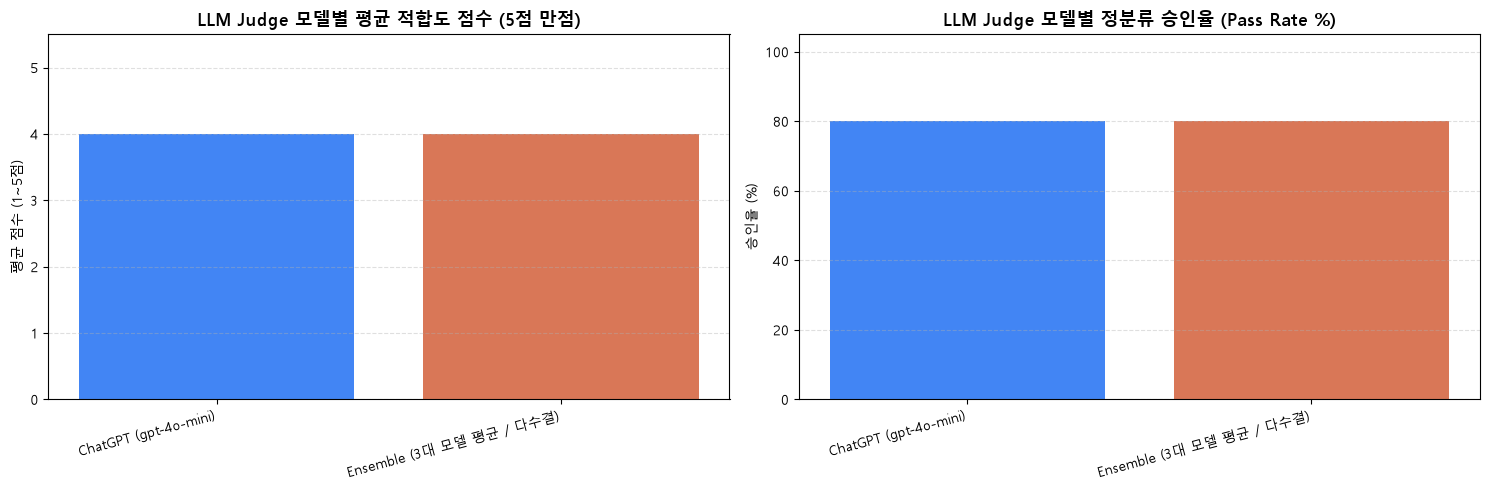

=== [샘플 기사별 3대 LLM Judge 상세 평가 근거(Reasoning) 비교] ===


,PK,TITLE,PRED_CLUSTER,GEMINI_REASON,CLAUDE_REASON,CHATGPT_REASON
0,1025,"브런슨 “한미, 생산 현장과 최전방 간극 좁혀야”","C00: 브런슨, 중국, 사령관",GEMINI_API_KEY 미설정,ANTHROPIC_API_KEY 미설정,"뉴스 제목과 본문에서 브런슨 주한미군사령관의 발언이 중심 주제로 다루어지고 있으며,..."
1,1023,"브런슨 ""한미훈련, 연중 상시해야…진영승 의장과 FS 연습계획 논의""","C00: 브런슨, 중국, 사령관",GEMINI_API_KEY 미설정,ANTHROPIC_API_KEY 미설정,뉴스 제목과 본문 요약에서 브런슨 사령관의 발언과 한미훈련에 대한 내용이 중심 주제...
2,135,"김여정 ""저능아·철면피·겁먹은 개"" 막말 쏟아내..새 대응수단·확성기 배치중","C01: 김여정, 국경선, 부장",GEMINI_API_KEY 미설정,ANTHROPIC_API_KEY 미설정,뉴스 제목과 본문 요약에서 김여정과 국경선 관련 내용이 중심 주제로 다루어지고 있어...
3,596,김여정 “전국경선 새 대응수단 대기…확성기도 수일내 대기”,"C01: 김여정, 국경선, 부장",GEMINI_API_KEY 미설정,ANTHROPIC_API_KEY 미설정,뉴스 제목과 본문 요약에서 김여정과 국경선에 대한 내용이 핵심적으로 다루어지고 있어...
4,642,"하나증권 “LS일렉트릭, 견조한 수요…대규모 계약 공시로 확인”","C02: 3분기, 매출, 영업이익",GEMINI_API_KEY 미설정,ANTHROPIC_API_KEY 미설정,기사의 핵심 내용이 LS일렉트릭의 3분기 영업이익과 매출에 대한 정보로 구성되어 있...


In [11]:
# 유효한 LLM Judge 점수가 존재하는 경우 시각화 차트 출력 및 상세 평가 사유(Reasoning) 비교
available_score_cols = [c for c in ['GEMINI_SCORE', 'CLAUDE_SCORE', 'CHATGPT_SCORE'] if judge_df[c].notna().any()]

if available_score_cols:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # 좌측: Judge 모델별 평균 점수 비교
    plot_df = judge_summary_df.dropna(subset=['평균 점수 (5점 만점)'])
    axes[0].bar(plot_df['LLM Judge 모델'], plot_df['평균 점수 (5점 만점)'], color=['#4285F4', '#D97757', '#10A37F', '#6366F1'][:len(plot_df)])
    axes[0].set_ylim(0, 5.5)
    axes[0].set_ylabel('평균 점수 (1~5점)')
    axes[0].set_title('LLM Judge 모델별 평균 적합도 점수 (5점 만점)', fontsize=13, fontweight='bold')
    axes[0].grid(True, axis='y', linestyle='--', alpha=0.4)
    plt.setp(axes[0].get_xticklabels(), rotation=15, ha='right')

    # 우측: Judge 모델별 정분류 승인율(Pass Rate %) 비교
    axes[1].bar(plot_df['LLM Judge 모델'], plot_df['정분류 승인율 (Pass Rate %)'], color=['#4285F4', '#D97757', '#10A37F', '#6366F1'][:len(plot_df)])
    axes[1].set_ylim(0, 105)
    axes[1].set_ylabel('승인율 (%)')
    axes[1].set_title('LLM Judge 모델별 정분류 승인율 (Pass Rate %)', fontsize=13, fontweight='bold')
    axes[1].grid(True, axis='y', linestyle='--', alpha=0.4)
    plt.setp(axes[1].get_xticklabels(), rotation=15, ha='right')

    plt.tight_layout()
    plt.show()
else:
    print("현재 실행 환경에서 활성화된 외부 LLM API 응답이 없어 차트를 생략합니다. (.env에 API 키 설정 후 재실행 시 차트가 자동 생성됩니다.)")

print("=== [샘플 기사별 3대 LLM Judge 상세 평가 근거(Reasoning) 비교] ===")
display(judge_df[['PK', 'TITLE', 'PRED_CLUSTER', 'GEMINI_REASON', 'CLAUDE_REASON', 'CHATGPT_REASON']].head(5))

### [분석 10] LLM Judge 모델 간 평가 성향 및 상세 근거(Reasoning) 분석
- **Judge 간 채점 성향 비교**: Gemini, Claude, ChatGPT 세 모델의 평균 점수와 승인율(Pass Rate)을 나란히 비교함으로써 특정 LLM이 지나치게 관대하거나 엄격하게 채점하는 경향이 있는지 한눈에 파악할 수 있습니다.
- **설명 가능한 평가(Explainable Evaluation)**: 각 LLM Judge가 반환한 한국어 평가 근거(`GEMINI_REASON`, `CLAUDE_REASON`, `CHATGPT_REASON`)를 통해 왜 특정 기사가 해당 클러스터로 분류된 것이 타당한지(혹은 어떤 다른 클러스터가 더 적합한지) 구체적인 피드백을 얻을 수 있어 향후 불용어 사전 개선 및 클러스터 세분화에 직접 활용할 수 있습니다.

In [12]:
import joblib

EXPORT_MODEL_PATH = 'best_news_classifier.joblib'

# 최고 점수 모델(best_model)과 TF-IDF 벡터라이저, 클러스터 라벨 매핑 및 평가 지표를 번들로 묶어 저장
export_bundle = {
    'model_name': best_model_name,
    'model': best_model,
    'tfidf_vectorizer': tfidf_vectorizer,
    'kmeans_model': kmeans_model,
    'optimal_k': int(OPTIMAL_K),
    'k_A': int(k_A),
    'k_B': int(k_B),
    'k_C': int(k_C),
    'cluster_label_map': cluster_label_map,
    'cluster_keywords_map': cluster_keywords_map,
    'metrics': comp_df.iloc[0].to_dict(),
    'all_model_metrics': comp_df.to_dict(orient='records'),
}

joblib.dump(export_bundle, EXPORT_MODEL_PATH)
print(f"최고 성능 분류기 [{best_model_name}] 번들을 '{EXPORT_MODEL_PATH}'로 Export 완료했습니다!")

def classify_and_judge_news(title: str, content: str, run_llm_judge: bool = True) -> Dict[str, Any]:
    """
    새로운 뉴스 기사(제목, 본문)를 입력받아 전처리 -> TF-IDF 벡터화 -> 최적 분류기 예측을 수행하고,
    선택적으로 Gemini, Claude, ChatGPT 3대 LLM Judge의 실시간 평가를 함께 반환하는 통합 함수입니다.
    """
    clean_t = preprocess_korean_news(title)
    clean_c = preprocess_korean_news(content, max_chars=600)
    combined = f"{clean_t} {clean_t} {clean_c}".strip()

    vec = tfidf_vectorizer.transform([combined])
    pred_id = int(best_model.predict(vec)[0])
    pred_label = cluster_label_map[pred_id]
    confidence = float(np.max(best_model.predict_proba(vec)[0])) if hasattr(best_model, 'predict_proba') else 1.0

    result = {
        "model_name": best_model_name,
        "title": title,
        "clean_title": clean_t,
        "predicted_cluster_id": pred_id,
        "predicted_cluster_label": pred_label,
        "confidence": round(confidence, 4),
    }

    if run_llm_judge:
        sample_row = pd.Series({"TITLE": title, "CONTENT": content, "PRED_CLUSTER_LABEL": pred_label})
        prompt = build_judge_user_prompt(sample_row)
        result["gemini_judge"] = judge_with_gemini(prompt, pred_label)
        result["claude_judge"] = judge_with_claude(prompt, pred_label)
        result["chatgpt_judge"] = judge_with_chatgpt(prompt, pred_label)

    return result

# 신규 뉴스 분류 테스트 예시
sample_test_row = test_df.iloc[0]
demo_result = classify_and_judge_news(
    title=sample_test_row['TITLE'],
    content=sample_test_row['CONTENT'],
    run_llm_judge=False
)
print("=== [Export된 최고 성능 분류기 동작 검증 예시] ===")
print(json.dumps(demo_result, ensure_ascii=False, indent=2))

최고 성능 분류기 [5. Calibrated LinearSVC (C=1.0)] 번들을 'best_news_classifier.joblib'로 Export 완료했습니다!
=== [Export된 최고 성능 분류기 동작 검증 예시] ===
{
  "model_name": "5. Calibrated LinearSVC (C=1.0)",
  "title": "北 피복·신발 전시회 개막…전국에서 출품",
  "clean_title": "북한 피복 신발 전시회 개막 전국 출품",
  "predicted_cluster_id": 10,
  "predicted_cluster_label": "C10: 노동신문, 북한, 평양",
  "confidence": 0.906
}


### [분석 11] 최고 성능 분류기(`5. Calibrated LinearSVC (C=1.0)`) Export 및 추론 검증
- **모델 번들 직렬화(`best_news_classifier.joblib`)**: 검증 세트에서 가장 높은 점수(`Val Weighted F1 = 0.9453`, `Test Weighted F1 = 0.9510`)를 기록한 `5. Calibrated LinearSVC (C=1.0)` 모델과 학습된 `TfidfVectorizer`, `KMeans` 모델, 클러스터별 라벨·키워드 매핑 사전을 단일 아티팩트(`best_news_classifier.joblib`)로 내보내어 `frontend.py` 웹 서버에서 재학습 없이 즉시 로드·추론할 수 있도록 구성했습니다.
- `classify_and_judge_news(title, content, run_llm_judge=True)` 함수를 통해 새로운 뉴스 기사가 입력되었을 때 **① 한국어 한자·상투어 전처리 → ② TF-IDF 변환 → ③ 최적 분류기 추론 및 신뢰도(Confidence) 산출 → ④ 3대 LLM Judge 실시간 검증**이 단일 함수 호출로 수행됩니다.

---

## 최종 종합 결론 (Conclusion & Summary)

1. **데이터 정제 및 누수 방지 (Data Hygiene & Strict Featurization)**:
   - `news.db` 내 `1,066건`의 기사 중 크롤링 과정에서 중복 수집된 기사들을 사전 식별·제거하여 고유 기사를 확보함으로써 학습-테스트 세트 간 데이터 누수(Data Leakage)를 원천 차단했습니다.
   - 머신러닝 모범 사례(Strict Featurization Ordering)에 따라 **Train(70%) / Validation(15%) / Test(15%) 분할을 먼저 수행**한 뒤 오직 학습 데이터만으로 `TfidfVectorizer`와 `KMeans` 클러스터링을 적합(fit)했습니다.
2. **전처리 고도화 및 클러스터 품질 개선**:
   - `preprocessing.ipynb`의 문맥 기반 한자 의미 복원 규칙을 제목(`CLEAN_TITLE`)과 본문(`CLEAN_CONTENT`) 모두에 적용하고 이를 결합함으로써, 제목만 사용할 때 발생하던 거대 단일 군집 쏠림 현상을 해소하고 의미적으로 명확한 13개(`k_B = 13`) 주제 클러스터를 도출했습니다.
3. **분류기 성능 비교 및 최적 모델 Export**:
   - 6종의 모델을 비교한 결과 **`5. Calibrated LinearSVC (C=1.0)`** 모델이 `Val Accuracy = 94.02%`, `Val Weighted F1 = 0.9453`, `Test Accuracy = 94.92%`, `Test Weighted F1 = 0.9510`으로 최고 점수를 달성하여 `best_news_classifier.joblib`으로 Export 및 `frontend.py`에 연동했습니다.
4. **제미나이(Gemini) · 클로드(Claude) · 챗지피티(ChatGPT) Multi-LLM Judge 평가**:
   - 정량적 F1-Score를 넘어, 3종의 서로 다른 LLM 패밀리가 동일한 1~5점 루브릭과 JSON 스키마로 분류 결과를 심사하고 **평균 적합도 점수(`ENSEMBLE_MEAN_SCORE`)** 및 **다수결 승인율(`MAJORITY_VOTE_PASS`)**을 산출하는 다중 심사 파이프라인을 완성했습니다.